# Checkpoint 07: Tích Hợp Toàn Diện Kết Hợp Phân Đoạn Từ VnCoreNLP (py_vncorenlp Segmentation)

Nghiên cứu: Nâng cao hiệu năng mô hình phát hiện phát ngôn thù ghét trên mạng xã hội tiếng Việt (ViHSD).

Mục tiêu khoa học và cơ sở lý thuyết:
1. **Bối cảnh thực nghiệm từ Checkpoint 05 và Checkpoint 06:**
   - Tại Checkpoint 05 (PhoBERT-base v1 kết hợp PyVi): Mô hình đạt Macro-F1 = 0.6686. Tuy nhiên, ranh giới tách từ của PyVi còn tồn tại một số sai lệch đối với các cụm từ ghép lóng và từ ngữ xúc phạm phức tạp.
   - Tại Checkpoint 06 (PhoBERT-base-v2 kết hợp PyVi): Mặc dù backbone hiện đại hơn, Macro-F1 lại bị sụt giảm xuống 0.6541 do Recall của lớp HATE tụt mạnh từ 0.6250 xuống 0.5581, bắt nguồn từ sự không tương thích giữa bộ tách từ PyVi và không gian từ vựng mới của PhoBERT-v2.
2. **Mục tiêu bứt phá của Checkpoint 07:**
   - Kết hợp **kiến trúc tối ưu của Checkpoint 05** với **công cụ phân đoạn từ chính thức `py_vncorenlp` (RDRsegmenter)** của VinAI Research nhằm đồng bộ 100% với không gian từ vựng FastBPE gốc của dòng mô hình PhoBERT.
   - Ứng dụng thuật toán Ripple Down Rules (RDR) với độ chính xác tách từ vượt trội (~97.9% so với ~96.0% của PyVi), loại bỏ triệt để hiện tượng phân mảnh token các từ ngữ thù ghét/xúc phạm.
3. **Khắc phục triệt để hiện tượng tụt Recall lớp HATE:**
   - Triển khai hàm mất mát **Weighted Focal Loss nâng cao** kết hợp hệ số điều chế mẫu khó $\gamma = 1.5$ (hoặc $2.0$) và vector trọng số lớp $\alpha$ được tinh chỉnh (Calibrated Smoothed Class Weights) nhằm gia tăng lực phạt có chủ đích cho các mẫu HATE và OFFENSIVE khó, kéo Recall của HATE vượt mốc 0.65 mà không làm suy giảm Precision của lớp CLEAN.
   - Tối ưu hóa chiến lược huấn luyện sâu: mở rộng ngữ cảnh `max_length = 256`, phân tầng tốc độ học ($2 \times 10^{-5}$ cho RoBERTa backbone / $1 \times 10^{-4}$ cho Classification Head), lịch trình Cosine Annealing with Warmup (10% warmup), 8 epochs và Early Stopping (patience = 2) theo dõi trực tiếp `eval_macro_f1`.
4. **Quy chuẩn xuất kết quả (Mandatory Artifacts Export):**
   - Xuất đầy đủ 4 tệp chuẩn hóa vào `outputs/checkpoint07/`: `predictions.csv`, `confusion_matrix_checkpoint07.png` & `confusion_matrix.csv`, `evaluation_scores.csv`, và `classification_report.csv`.

Ghi chú: Toàn bộ mã nguồn định nghĩa bộ tiền xử lý tích hợp `py_vncorenlp`, Dataset, hàm mất mát Weighted Focal Loss, Optimizer phân tầng và đánh giá được tích hợp 100% trong notebook để chạy độc lập (Self-contained) trên Google Colab.

In [1]:
import os
import sys

# Thiết lập môi trường làm việc và kết nối Google Drive trên Google Colab
try:
    from google.colab import drive
    drive.mount('/content/drive')
    project_dir = '/content/drive/MyDrive/NLP_PhoBert_ViHSD'
except ImportError:
    project_dir = os.path.abspath('..')

checkpoints_dir = os.path.join(project_dir, 'checkpoints', 'checkpoint07')
outputs_dir = os.path.join(project_dir, 'outputs', 'checkpoint07')
vncorenlp_dir = os.path.join(project_dir, 'vncorenlp')

os.makedirs(checkpoints_dir, exist_ok=True)
os.makedirs(outputs_dir, exist_ok=True)
os.makedirs(vncorenlp_dir, exist_ok=True)

print(f'Thư mục dự án: {project_dir}')
print(f'Thư mục lưu checkpoint: {checkpoints_dir}')
print(f'Thư mục lưu kết quả: {outputs_dir}')
print(f'Thư mục lưu mô hình VnCoreNLP: {vncorenlp_dir}')

Mounted at /content/drive
Thư mục dự án: /content/drive/MyDrive/NLP_PhoBert_ViHSD
Thư mục lưu checkpoint: /content/drive/MyDrive/NLP_PhoBert_ViHSD/checkpoints/checkpoint07
Thư mục lưu kết quả: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint07
Thư mục lưu mô hình VnCoreNLP: /content/drive/MyDrive/NLP_PhoBert_ViHSD/vncorenlp


In [2]:
# Cài đặt OpenJDK và các thư viện cần thiết trên môi trường Google Colab / Linux
# py_vncorenlp yêu cầu môi trường Java 1.8+ để khởi chạy tiến trình RDRsegmenter
!apt-get update -qq && apt-get install -y -qq openjdk-11-jdk-headless
!pip install -q py_vncorenlp pyvi transformers accelerate scikit-learn seaborn matplotlib pandas numpy torch

# Kiểm tra phiên bản Java để đảm bảo VnCoreNLP hoạt động ổn định và chính xác
!java -version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Selecting previously unselected package openjdk-11-jre-headless:amd64.
(Reading database ... 127324 files and directories currently installed.)
Preparing to unpack .../openjdk-11-jre-headless_11.0.33+9-1ubuntu1~24.04.1_amd64.deb ...
Unpacking openjdk-11-jre-headless:amd64 (11.0.33+9-1ubuntu1~24.04.1) ...
Selecting previously unselected package openjdk-11-jdk-headless:amd64.
Preparing to unpack .../openjdk-11-jdk-headless_11.0.33+9-1ubuntu1~24.04.1_amd64.deb ...
Unpacking openjdk-11-jdk-headless:amd64 (11.0.33+9-1ubuntu1~24.04.1) ...
Setting up openjdk-11-jre-headless:amd64 (11.0.33+9-1ubuntu1~24.04.1) ...
update-alternatives: using /usr/lib/jvm/java-11-openjdk-amd64/bin/jjs to provide /usr/bin/jjs (jjs) in auto mode
update-alternatives: using /usr/lib/jvm/java-11-openjdk-amd64/bin/rmid to provide /us

In [3]:
# Thiết lập hạt giống ngẫu nhiên cố định để đảm bảo tính tái lập thực nghiệm
random_seed = 42

import os
import random
import numpy as np
import torch

os.environ['PYTHONHASHSEED'] = str(random_seed)
random.seed(random_seed)
np.random.seed(random_seed)
torch.manual_seed(random_seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed(random_seed)
    torch.cuda.manual_seed_all(random_seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

print(f'Thiết lập random seed thành công: {random_seed}')

Thiết lập random seed thành công: 42


## 1. Nạp Tập Dữ Liệu Thô và Kiểm Tra Trước Xử Lý (Pre-pipeline Verification)

In [4]:
# Cấu hình đường dẫn tập dữ liệu
data_dir = 'data' if os.path.exists('data/train.csv') else os.path.join(project_dir, 'data')
train_path = os.path.join(data_dir, 'train.csv')
dev_path = os.path.join(data_dir, 'dev.csv')
test_path = os.path.join(data_dir, 'test.csv')

import pandas as pd

train_raw = pd.read_csv(train_path)
dev_raw = pd.read_csv(dev_path)
test_raw = pd.read_csv(test_path)

assert len(train_raw) == 24048, f'Số lượng mẫu train không khớp: {len(train_raw)}'
assert len(dev_raw) == 2672, f'Số lượng mẫu dev không khớp: {len(dev_raw)}'
assert len(test_raw) == 6680, f'Số lượng mẫu test không khớp: {len(test_raw)}'

print('Kiểm tra tập dữ liệu thô trước xử lý:')
print(f'- Train: {len(train_raw)} mẫu, null: {train_raw["free_text"].isna().sum()}')
print(f'- Dev:   {len(dev_raw)} mẫu, null: {dev_raw["free_text"].isna().sum()}')
print(f'- Test:  {len(test_raw)} mẫu, null: {test_raw["free_text"].isna().sum()}')

Kiểm tra tập dữ liệu thô trước xử lý:
- Train: 24048 mẫu, null: 2
- Dev:   2672 mẫu, null: 0
- Test:  6680 mẫu, null: 0


## 2. Định Nghĩa Bộ Tiền Xử Lý Tích Hợp VnCoreNLP (ViHSDPreprocessor with py_vncorenlp)

Module tiền xử lý `ViHSDPreprocessor` được thiết kế tự chứa (100% self-contained) với 6 mắt xích chuẩn hóa chuyên sâu:
1. **Làm sạch cấu trúc & ký tự đặc biệt:** Chuẩn hóa Unicode dựng sẵn (NFC), xóa URL, thẻ HTML, loại bỏ ký tự ngắt dòng `\r`, `\n`, `\t` nhằm xử lý văn bản đa dòng mượt mà.
2. **Ánh xạ Emoji 2 pha (Two-phase Emoji Mapping):** Đệm khoảng trắng cách ly emoji để tránh lỗi dính từ, sau đó chuyển đổi emoji thành các từ tố biểu cảm tiếng Việt mang tính phân cực cảm xúc (`emojis.csv`).
3. **Chuẩn hóa Teencode & tiếng lóng 412 quy tắc (`teencode.csv`):** Chuyển đổi các từ viết tắt, tiếng lóng và ký tự né bộ lọc kiểm duyệt mạng xã hội về dạng tiếng Việt chuẩn tắc.
4. **Thu gọn ký tự lặp kéo dài cảm xúc:** Rút gọn các ký tự kéo dài (`ngonnnnn` $\to$ `ngon`, `haizzzzz` $\to$ `haiz`).
5. **Phân đoạn từ tiếng Việt bằng VnCoreNLP RDRsegmenter:** Ứng dụng thuật toán Ripple Down Rules chính thức của PhoBERT để nối từ ghép bằng dấu gạch dưới (`học_sinh`, `xúc_phạm`), đồng bộ 100% với không gian từ vựng FastBPE gốc. Xử lý an toàn chống lỗi deadlock JVM.
6. **Bảo tồn tuyệt đối đại từ nhân xưng và từ phủ định:** Bãi bỏ hoàn toàn việc lọc stopwords thông thường. Giữ nguyên đại từ (`mày`, `tao`, `nó`, `thằng`, `con`) để xác định đối tượng công kích và từ phủ định (`không`, `chẳng`, `chả`) để định vị cực tính câu nói.

In [5]:
import csv
import os
import re
import unicodedata
import numpy as np
import pandas as pd

try:
    from pyvi import ViTokenizer
except ImportError:
    ViTokenizer = None


class ViHSDPreprocessor:
    """
    Bộ tiền xử lý và chuẩn hóa dữ liệu tiếng Việt mạng xã hội tự chứa (Self-contained).
    Tích hợp trực tiếp công cụ phân đoạn từ VnCoreNLP (RDRsegmenter) của VinAI Research,
    chuẩn hóa Teencode 412 quy tắc, ánh xạ biểu cảm Emoji 2 pha và bảo tồn đại từ / từ phủ định.
    """

    def __init__(self, teencode_path, emoji_path, segmenter=None):
        self.segmenter = segmenter
        self.teencode_dict = self._load_teencode_dict(teencode_path)
        self.emoji_dict = self._load_emoji_dict(emoji_path)

        # Biên dịch sẵn các biểu thức chính quy (Regex) để tối ưu hóa tốc độ xử lý
        self.url_pattern = re.compile(r'https?://\S+|www\.\S+')
        self.whitespace_pattern = re.compile(r'\s+')
        self.special_char_pattern = re.compile(r'[\r\n\t]+')
        self.lengthening_pattern = re.compile(r'([a-zA-ZÀ-ỹ])\1{2,}', re.IGNORECASE)

        # Xây dựng regex cho Teencode với ranh giới từ (\b) để tránh thay thế nhầm từ con
        escaped_teencode = [re.escape(k) for k in sorted(self.teencode_dict.keys(), key=len, reverse=True)]
        self.teencode_pattern = re.compile(r'\b(' + '|'.join(escaped_teencode) + r')\b', re.IGNORECASE) if escaped_teencode else None

        # Xây dựng regex cho Emoji
        escaped_emojis = [re.escape(k) for k in sorted(self.emoji_dict.keys(), key=len, reverse=True)]
        self.emoji_pattern = re.compile('(' + '|'.join(escaped_emojis) + ')') if escaped_emojis else None

    def _load_teencode_dict(self, path):
        """Đọc và chuẩn hóa từ điển Teencode từ tệp CSV."""
        df = pd.read_csv(path)
        col_key = 'teencode' if 'teencode' in df.columns else df.columns[0]
        col_val = 'replacement' if 'replacement' in df.columns else ('standard' if 'standard' in df.columns else df.columns[1])
        return dict(zip(
            df[col_key].astype(str).str.strip().str.lower(),
            df[col_val].astype(str).str.strip().str.lower()
        ))

    def _load_emoji_dict(self, path):
        """Đọc và chuẩn hóa từ điển Emoji từ tệp CSV."""
        df = pd.read_csv(path)
        col_key = 'emoji' if 'emoji' in df.columns else df.columns[0]
        col_val = 'replacement' if 'replacement' in df.columns else ('meaning' if 'meaning' in df.columns else df.columns[1])
        return dict(zip(
            df[col_key].astype(str).str.strip(),
            df[col_val].astype(str).str.strip()
        ))

    def clean_special_characters(self, text):
        """
        Làm sạch ký tự lạ, chuẩn hóa Unicode NFC và xử lý văn bản đa dòng (\r, \n, \t).
        """
        text = unicodedata.normalize('NFC', text)
        text = self.url_pattern.sub(' ', text)
        text = self.special_char_pattern.sub(' ', text)
        return self.whitespace_pattern.sub(' ', text).strip()

    def pad_and_map_emojis(self, text):
        """
        Ánh xạ Emoji 2 pha:
        - Pha 1: Đệm khoảng cách hai bên ký tự emoji để chống dính từ khi tách từ.
        - Pha 2: Chuyển đổi mã Unicode emoji thành từ tố mang sắc thái cảm xúc tiếng Việt.
        """
        if self.emoji_pattern is None:
            return text
        text = self.emoji_pattern.sub(lambda m: f' {self.emoji_dict.get(m.group(0), "")} ', text)
        return self.whitespace_pattern.sub(' ', text).strip()

    def normalize_teencode(self, text):
        """
        Chuẩn hóa từ viết tắt, tiếng lóng mạng xã hội và từ né kiểm duyệt về dạng chuẩn.
        Phục hồi đại từ nhân xưng (m -> mày, t -> tao) và từ phủ định (k/ko -> không).
        """
        if self.teencode_pattern is None:
            return text
        return self.teencode_pattern.sub(lambda m: self.teencode_dict.get(m.group(0).lower(), m.group(0)), text)

    def reduce_lengthening(self, text):
        """Thu gọn ký tự kéo dài cảm xúc về 1 ký tự chuẩn (ví dụ: ngonnnnn -> ngon)."""
        return self.lengthening_pattern.sub(r'\1', text)

    def segment_words(self, text):
        """
        Phân đoạn từ tiếng Việt bằng VnCoreNLP RDRsegmenter (thuật toán Ripple Down Rules).
        Bảo vệ tiến trình thực thi an toàn trên JVM, xử lý văn bản đa dòng và danh sách rỗng.
        """
        if not text or not text.strip():
            return ''

        # Đảm bảo văn bản là chuỗi một dòng trước khi gửi tới VnCoreNLP
        cleaned_single_line = self.whitespace_pattern.sub(' ', text).strip()
        if not cleaned_single_line:
            return ''

        if self.segmenter is not None:
            try:
                sentences = self.segmenter.word_segment(cleaned_single_line)
                if isinstance(sentences, list):
                    segmented_result = ' '.join(sentences).strip()
                else:
                    segmented_result = str(sentences).strip()
                if segmented_result:
                    return segmented_result
            except Exception:
                # Nếu xảy ra trục trặc trên JVM, tự động chuyển đổi sang PyVi
                pass

        if ViTokenizer is not None:
            return ViTokenizer.tokenize(cleaned_single_line)
        return cleaned_single_line

    def transform_text(self, text, lowercased=False):
        """
        Thực thi toàn bộ luồng tiền xử lý theo đúng trình tự khoa học:
        Làm sạch ký tự -> Emoji 2 pha -> Teencode 412 -> Thu gọn ký tự lặp -> Tách từ VnCoreNLP.
        Tuyệt đối không loại bỏ từ dừng nhằm bảo tồn đại từ nhân xưng và từ phủ định.
        """
        if not isinstance(text, str):
            text = str(text) if text is not None else ''
        if not text.strip():
            return ''

        # 1. Làm sạch ký tự đặc biệt, URL, khoảng trắng đa dòng
        text = self.clean_special_characters(text)
        # 2. Ánh xạ biểu cảm Emoji 2 pha
        text = self.pad_and_map_emojis(text)
        # 3. Chuẩn hóa Teencode 412 quy tắc
        text = self.normalize_teencode(text)
        # 4. Thu gọn ký tự lặp kéo dài
        text = self.reduce_lengthening(text)
        # 5. Phân đoạn từ tiếng Việt bằng VnCoreNLP RDRsegmenter
        if text.strip():
            text = self.segment_words(text)
        # 6. Hạ chữ thường (tùy chọn)
        if lowercased:
            text = text.lower()

        return self.whitespace_pattern.sub(' ', text).strip()

    def transform_dataset(self, df, text_col='free_text', label_col='label_id', lowercased=False):
        """
        Tiền xử lý toàn bộ tập dữ liệu DataFrame, loại bỏ mẫu rỗng và đảm bảo căn chỉnh mượt mà giữa X và y.
        """
        df_clean = df.dropna(subset=[text_col, label_col]).copy()
        df_clean[label_col] = df_clean[label_col].astype(int)
        transformed_texts = []
        valid_indices = []

        for idx, row in df_clean.iterrows():
            cleaned_text = self.transform_text(row[text_col], lowercased=lowercased)
            if cleaned_text:
                transformed_texts.append(cleaned_text)
                valid_indices.append(idx)

        filtered_df = df_clean.loc[valid_indices].copy()
        return transformed_texts, filtered_df[label_col].to_numpy()

## 3. Khởi Tạo VnCoreNLP (RDRsegmenter) và Thực Hiện Tiền Xử Lý Dữ Liệu

Sử dụng `py_vncorenlp.VnCoreNLP(annotators=['wseg'])` - công cụ phân đoạn từ chính thức được VinAI Research khuyến nghị cho dòng mô hình PhoBERT.

In [6]:
teencode_path = os.path.join(data_dir, 'teencode.csv')
emoji_path = os.path.join(data_dir, 'emojis.csv')

import jnius_config
import py_vncorenlp

# Tải mô hình VnCoreNLP nếu chưa tồn tại trong thư mục dự án
try:
    py_vncorenlp.download_model(save_dir=vncorenlp_dir)
except Exception as e:
    print(f'Thông báo tải model VnCoreNLP: {e}')

# Khởi tạo an toàn VnCoreNLP RDRsegmenter (xử lý xung đột khi JVM đã khởi chạy trong session hiện tại)
def initialize_vncorenlp_safe(save_dir, annotators=['wseg']):
    """
    Khởi tạo VnCoreNLP an toàn, tránh lỗi 'VM is already running' khi chạy lại cell trong Google Colab.
    Chỉ nạp duy nhất annotator 'wseg' để tối ưu tốc độ phân đoạn từ và tiết kiệm tài nguyên bộ nhớ.
    """
    current_dir = os.getcwd()
    orig_check_vm = getattr(jnius_config, 'check_vm_running', None)
    try:
        # Tạm thời bỏ qua kiểm tra check_vm_running nếu JVM đã khởi động trước đó trong phiên Colab
        if orig_check_vm is not None:
            jnius_config.check_vm_running = lambda: None
        segmenter = py_vncorenlp.VnCoreNLP(annotators=annotators, save_dir=save_dir)
        return segmenter
    finally:
        # Phục hồi hàm kiểm tra gốc và khôi phục thư mục làm việc ban đầu
        if orig_check_vm is not None:
            jnius_config.check_vm_running = orig_check_vm
        if os.getcwd() != current_dir:
            os.chdir(current_dir)

if 'rdrsegmenter' in globals() and rdrsegmenter is not None:
    print('Tái sử dụng đối tượng rdrsegmenter đã tồn tại trong phiên làm việc.')
else:
    print(f'Khởi tạo VnCoreNLP RDRsegmenter (annotators=["wseg"]) từ: {vncorenlp_dir}...')
    rdrsegmenter = initialize_vncorenlp_safe(save_dir=vncorenlp_dir, annotators=['wseg'])
    print('Khởi tạo thành công bộ tách từ VnCoreNLP RDRsegmenter!')

preprocessor = ViHSDPreprocessor(
    teencode_path=teencode_path,
    emoji_path=emoji_path,
    segmenter=rdrsegmenter,
)

# Kiểm tra trực quan mẫu tiền xử lý và phân đoạn từ với VnCoreNLP
sample_test = "Đm thằng này nhìn mặt hãm vl 😡 ko biết nhục à"
print('Kiểm tra trực quan mẫu tiền xử lý:')
print(f'- Văn bản gốc: {sample_test}')
print(f'- Sau xử lý:   {preprocessor.transform_text(sample_test)}')

print('Bắt đầu tiền xử lý và phân đoạn từ bằng VnCoreNLP trên ba tập dữ liệu...')
train_X, train_y = preprocessor.transform_dataset(train_raw)
dev_X, dev_y = preprocessor.transform_dataset(dev_raw)
test_X, test_y = preprocessor.transform_dataset(test_raw)

assert len(train_X) == len(train_y), 'Số lượng train X và y không khớp'
assert len(dev_X) == len(dev_y), 'Số lượng dev X và y không khớp'
assert len(test_X) == len(test_y), 'Số lượng test X và y không khớp'
assert sum(len(x.strip()) == 0 for x in train_X) == 0, 'Tồn tại văn bản rỗng trong train_X'

print('Tiền xử lý hoàn tất thành công:')
print(f'- Train: {len(train_X)} mẫu')
print(f'- Dev:   {len(dev_X)} mẫu')
print(f'- Test:  {len(test_X)} mẫu')

Khởi tạo VnCoreNLP RDRsegmenter (annotators=["wseg"]) từ: /content/drive/MyDrive/NLP_PhoBert_ViHSD/vncorenlp...
Khởi tạo thành công bộ tách từ VnCoreNLP RDRsegmenter!
Kiểm tra trực quan mẫu tiền xử lý:
- Văn bản gốc: Đm thằng này nhìn mặt hãm vl 😡 ko biết nhục à
- Sau xử lý:   đụ má thằng này nhìn mặt hãm vãi lồn tức _ giận không biết nhục à
Bắt đầu tiền xử lý và phân đoạn từ bằng VnCoreNLP trên ba tập dữ liệu...
Tiền xử lý hoàn tất thành công:
- Train: 24046 mẫu
- Dev:   2672 mẫu
- Test:  6680 mẫu


## 4. Định Nghĩa Lớp BuildDataset và Mã Hóa Chuỗi Mở Rộng (max_length = 256)

In [7]:
pretrained_model_name = 'vinai/phobert-base'
max_seq_length = 256

import torch
from transformers import AutoTokenizer


class BuildDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx], dtype=torch.long)
        return item

    def __len__(self):
        return len(self.labels)


print(f'Khởi tạo Tokenizer: {pretrained_model_name} (use_fast=False, max_length={max_seq_length})')
tokenizer = AutoTokenizer.from_pretrained(pretrained_model_name, use_fast=False)

train_encodings = tokenizer(train_X, truncation=True, padding=True, max_length=max_seq_length)
dev_encodings = tokenizer(dev_X, truncation=True, padding=True, max_length=max_seq_length)
test_encodings = tokenizer(test_X, truncation=True, padding=True, max_length=max_seq_length)

train_dataset = BuildDataset(train_encodings, train_y)
dev_dataset = BuildDataset(dev_encodings, dev_y)
test_dataset = BuildDataset(test_encodings, test_y)

print(f'Kích thước tập train sau mã hóa: {len(train_dataset)}')
print(f'Kích thước tập dev sau mã hóa:   {len(dev_dataset)}')
print(f'Kích thước tập test sau mã hóa:  {len(test_dataset)}')

Khởi tạo Tokenizer: vinai/phobert-base (use_fast=False, max_length=256)


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/557 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/895k [00:00<?, ?B/s]

bpe.codes:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.13M [00:00<?, ?B/s]

Kích thước tập train sau mã hóa: 24046
Kích thước tập dev sau mã hóa:   2672
Kích thước tập test sau mã hóa:  6680


## 5. Tính Toán Vector Trọng Số Lớp Tinh Chỉnh và Định Nghĩa Weighted Focal Loss Nâng Cao

Để giải quyết triệt để hiện tượng tụt Recall của lớp HATE (từng ghi nhận ở CP06 chỉ đạt 0.5581), Checkpoint 07 áp dụng hàm mất mát **Weighted Focal Loss nâng cao**:
$$\mathcal{L}_{WFL}(p_t) = -\alpha_t (1 - p_t)^\gamma \log(p_t)$$

Trong đó:
1. **Hệ số điều chế mẫu khó $\gamma = 1.5$:** Tự động triệt tiêu gradient tổn thất từ các mẫu CLEAN dễ phân loại, tập trung tài nguyên tối ưu vào các mẫu thù ghét tinh vi. (Hỗ trợ thử nghiệm nâng lên $\gamma = 2.0$ để phạt gắt hơn).
2. **Vector trọng số $\alpha$ tinh chỉnh (Calibrated Smoothed Class Weights):**
   - Trong phân bố gốc của ViHSD, lớp OFFENSIVE có 1.611 mẫu và HATE có 2.541 mẫu. Do đó, công thức nghịch đảo tần suất thông thường vô tình gán trọng số lớp HATE nhỏ hơn đáng kể so với OFFENSIVE ($\alpha_{\text{HATE}} \approx 1.14 < \alpha_{\text{OFFENSIVE}} \approx 1.44$).
   - Sự mất cân đối này khiến mô hình ưu tiên né lỗi lớp OFFENSIVE hơn, làm suy giảm độ nhạy (Recall) của lớp HATE.
   - Checkpoint 07 hiệu chỉnh trọng số $\alpha$ (thông qua cơ chế làm mịn căn bậc hai có căn chỉnh lực phạt hoặc Mild Power-Law) nhằm nâng trọng số của lớp HATE lên mức tương xứng ($\approx 1.25 - 1.35$), đủ sức thúc đẩy Recall lớp HATE vượt mốc 0.65 mà vẫn bảo toàn độ chuẩn xác (Precision) của lớp CLEAN.

In [8]:
# ==============================================================================
# KHAI BÁO SIÊU THAM SỐ HÀM MẤT MÁT VÀ VECTOR TRỌNG SỐ LỚP
# ==============================================================================
focal_gamma = 1.5               # Tham số điều chế độ khó (gamma = 1.5 chuẩn; có thể đặt 2.0 nếu muốn phạt gắt mẫu khó)
weighting_method = 'calibrated_smoothed'  # Phương pháp tính alpha: 'calibrated_smoothed', 'smoothed', 'mild_power_law'
hate_recall_boost = 1.15        # Hệ số tăng cường trọng số phạt cho lớp HATE nhằm kéo Recall > 0.65

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
from transformers import Trainer, get_cosine_schedule_with_warmup


def compute_class_weights(labels, method='calibrated_smoothed', power=0.5, hate_boost=1.15):
    """
    Tính toán vector trọng số alpha xử lý mất cân bằng nhãn trên ViHSD.

    Phương pháp:
    1. 'calibrated_smoothed': Làm mịn căn bậc hai có hiệu chỉnh lực phạt cho lớp HATE để khắc phục tụt Recall.
    2. 'smoothed': Làm mịn căn bậc hai tiêu chuẩn: w_c proportional to sqrt(N / N_c).
    3. 'mild_power_law': Trọng số lũy thừa làm dịu: w_c proportional to (N / N_c)^power (power in [0.25, 0.40]).
    """
    labels = np.asarray(labels, dtype=int)
    total_samples = len(labels)
    classes, counts = np.unique(labels, return_counts=True)
    counts_float = counts.astype(np.float64)

    if method == 'smoothed':
        raw_weights = np.sqrt(total_samples / counts_float)
    elif method == 'mild_power_law':
        raw_weights = np.power(total_samples / counts_float, power)
    elif method == 'calibrated_smoothed':
        raw_weights = np.sqrt(total_samples / counts_float)
        if len(raw_weights) > 2:
            raw_weights[2] *= hate_boost  # Tăng cường phạt sai số lớp HATE để tối ưu Recall
    else:
        raw_weights = np.ones_like(counts_float)

    # Chuẩn hóa vector trọng số để trung bình cộng bằng 1
    normalized_weights = raw_weights / np.mean(raw_weights)
    return torch.tensor(normalized_weights, dtype=torch.float32), dict(zip(classes, counts))


active_class_weights, class_counts = compute_class_weights(
    train_y,
    method=weighting_method,
    hate_boost=hate_recall_boost
)

print('Phân bố nhãn trong tập huấn luyện:', class_counts)
print(f'Phương pháp tính trọng số: {weighting_method} (hate_boost={hate_recall_boost})')
print(f'Vector alpha trọng số lớp áp dụng: {active_class_weights.tolist()}')
print(f'  - alpha CLEAN:     {active_class_weights[0]:.4f}')
print(f'  - alpha OFFENSIVE: {active_class_weights[1]:.4f}')
print(f'  - alpha HATE:      {active_class_weights[2]:.4f}')


class WeightedFocalLoss(nn.Module):
    """
    Hàm mất mát Weighted Focal Loss nâng cao:
    - Cơ chế điều chế mẫu khó (1 - p_t)^gamma triệt tiêu gradient của mẫu CLEAN dễ.
    - Vector trọng số alpha tinh chỉnh gia tăng lực phạt trên mẫu HATE / OFFENSIVE.
    """

    def __init__(self, alpha=None, gamma=1.5, reduction='mean'):
        super().__init__()
        self.gamma = gamma
        self.alpha = alpha
        self.reduction = reduction

    def forward(self, logits, targets):
        ce_loss = F.cross_entropy(logits, targets, reduction='none')
        pt = torch.exp(-ce_loss)
        modulating_factor = (1.0 - pt) ** self.gamma
        focal_loss = modulating_factor * ce_loss

        if self.alpha is not None:
            if isinstance(self.alpha, torch.Tensor):
                alpha_t = self.alpha.to(logits.device)[targets]
                focal_loss = alpha_t * focal_loss
            else:
                focal_loss = self.alpha * focal_loss

        return focal_loss.mean() if self.reduction == 'mean' else focal_loss


class CombinedOptimizedTrainer(Trainer):
    """
    Trainer tích hợp đồng thời:
    - Hàm mất mát Weighted Focal Loss nâng cao.
    - Phân tầng tốc độ học (Differential Learning Rates): 2e-5 cho RoBERTa backbone, 1e-4 cho Classifier Head.
    - Lịch trình Cosine Annealing with Warmup (10% warmup steps).
    """

    def __init__(self, *args, loss_fn=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.loss_fn = loss_fn if loss_fn is not None else WeightedFocalLoss()

    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None, **kwargs):
        labels = inputs.get('labels')
        outputs = model(**inputs)
        logits = outputs.get('logits')
        loss = self.loss_fn(logits, labels)
        return (loss, outputs) if return_outputs else loss

    def create_optimizer_and_scheduler(self, num_training_steps: int):
        roberta_decay = [p for n, p in self.model.named_parameters() if 'roberta' in n and not any(nd in n for nd in ['bias', 'LayerNorm.weight'])]
        roberta_no_decay = [p for n, p in self.model.named_parameters() if 'roberta' in n and any(nd in n for nd in ['bias', 'LayerNorm.weight'])]
        classifier_decay = [p for n, p in self.model.named_parameters() if 'roberta' not in n and not any(nd in n for nd in ['bias', 'LayerNorm.weight'])]
        classifier_no_decay = [p for n, p in self.model.named_parameters() if 'roberta' not in n and any(nd in n for nd in ['bias', 'LayerNorm.weight'])]

        optimizer_grouped_parameters = [
            {'params': roberta_decay, 'lr': 2e-5, 'weight_decay': 0.01},
            {'params': roberta_no_decay, 'lr': 2e-5, 'weight_decay': 0.0},
            {'params': classifier_decay, 'lr': 1e-4, 'weight_decay': 0.01},
            {'params': classifier_no_decay, 'lr': 1e-4, 'weight_decay': 0.0},
        ]

        self.optimizer = AdamW(optimizer_grouped_parameters)
        warmup_steps = int(num_training_steps * 0.10)
        self.lr_scheduler = get_cosine_schedule_with_warmup(
            self.optimizer,
            num_warmup_steps=warmup_steps,
            num_training_steps=num_training_steps,
        )
        print(f'Đã khởi tạo Optimizer phân tầng (RoBERTa: 2e-5, Classifier Head: 1e-4, Cosine Warmup: 10%).')
        return self.optimizer, self.lr_scheduler

weighted_focal_loss_fn = WeightedFocalLoss(alpha=active_class_weights, gamma=focal_gamma)
print(f'Đã khởi tạo WeightedFocalLoss(gamma={focal_gamma}, alpha=calibrated_weights) thành công.')

Phân bố nhãn trong tập huấn luyện: {np.int64(0): np.int64(19885), np.int64(1): np.int64(1605), np.int64(2): np.int64(2556)}
Phương pháp tính trọng số: calibrated_smoothed (hate_boost=1.15)
Vector alpha trọng số lớp áp dụng: [0.3882259130477905, 1.3665006160736084, 1.245273470878601]
  - alpha CLEAN:     0.3882
  - alpha OFFENSIVE: 1.3665
  - alpha HATE:      1.2453
Đã khởi tạo WeightedFocalLoss(gamma=1.5, alpha=calibrated_weights) thành công.


## 6. Cấu Hình Siêu Tham Số Huấn Luyện và Dừng Sớm (Early Stopping)

In [9]:
num_labels = 3
num_epochs = 8
train_batch_size = 16
eval_batch_size = 16
gradient_accumulation_steps = 2
weight_decay = 0.01

import numpy as np
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score
from transformers import AutoModelForSequenceClassification, EarlyStoppingCallback, TrainingArguments


def compute_metrics_eval(eval_pred):
    predictions, labels = eval_pred
    preds = np.argmax(predictions, axis=-1)
    acc = accuracy_score(labels, preds)
    macro_p = precision_score(labels, preds, average='macro', zero_division=0)
    macro_r = recall_score(labels, preds, average='macro', zero_division=0)
    macro_f1 = f1_score(labels, preds, average='macro')
    micro_f1 = f1_score(labels, preds, average='micro')
    per_class_f1 = f1_score(labels, preds, average=None)
    return {
        'accuracy': acc,
        'macro_precision': macro_p,
        'macro_recall': macro_r,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'f1_clean': per_class_f1[0] if len(per_class_f1) > 0 else 0.0,
        'f1_offensive': per_class_f1[1] if len(per_class_f1) > 1 else 0.0,
        'f1_hate': per_class_f1[2] if len(per_class_f1) > 2 else 0.0,
    }


model = AutoModelForSequenceClassification.from_pretrained(pretrained_model_name, num_labels=num_labels)

training_args = TrainingArguments(
    output_dir=checkpoints_dir,
    num_train_epochs=num_epochs,
    per_device_train_batch_size=train_batch_size,
    per_device_eval_batch_size=eval_batch_size,
    gradient_accumulation_steps=gradient_accumulation_steps,
    weight_decay=weight_decay,
    do_eval=True,
    eval_strategy='epoch',
    save_strategy='epoch',
    save_total_limit=2,
    load_best_model_at_end=True,
    metric_for_best_model='macro_f1',
    greater_is_better=True,
    fp16=torch.cuda.is_available(),
    logging_steps=50,
    seed=random_seed,
)

trainer = CombinedOptimizedTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=dev_dataset,
    compute_metrics=compute_metrics_eval,
    loss_fn=weighted_focal_loss_fn,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)

print('Khởi tạo CombinedOptimizedTrainer thành công cho Checkpoint 07 (VnCoreNLP).')

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  543MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B /  543MB            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

model.safetensors: downloading bytes:           |  0.00B            

[transformers] RobertaForSequenceClassification LOAD REPORT from: vinai/phobert-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.decoder.weight      | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.decoder.bias        | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.bias       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Khởi tạo CombinedOptimizedTrainer thành công cho Checkpoint 07 (VnCoreNLP).


## 7. Huấn Luyện Mô Hình và Lưu Checkpoint Tối Ưu

In [10]:
print('Bắt đầu huấn luyện Checkpoint 07 (Combined + VnCoreNLP)...')
train_result = trainer.train()

save_model_dir = os.path.join(checkpoints_dir, 'final_model')
trainer.save_model(save_model_dir)
tokenizer.save_pretrained(save_model_dir)
print(f'Đã lưu mô hình tối ưu nhất tại: {save_model_dir}')

Bắt đầu huấn luyện Checkpoint 07 (Combined + VnCoreNLP)...


Epoch,Training Loss,Validation Loss,Accuracy,Macro Precision,Macro Recall,Macro F1,Micro F1,F1 Clean,F1 Offensive,F1 Hate
1,0.304531,0.178265,0.822979,0.601651,0.652687,0.599788,0.822979,0.913539,0.331395,0.554430
2,0.232704,0.177973,0.857784,0.663431,0.677228,0.664832,0.857784,0.933026,0.490040,0.571429
3,0.176526,0.226116,0.854416,0.659092,0.683773,0.665916,0.854416,0.929942,0.486275,0.581532
4,0.161586,0.242628,0.844311,0.633612,0.693673,0.658832,0.844311,0.923474,0.447581,0.605442
5,0.061422,0.338313,0.873877,0.701470,0.680603,0.690589,0.873877,0.937202,0.509804,0.624762
6,0.038319,0.378441,0.864521,0.675907,0.678011,0.676219,0.864521,0.933973,0.510067,0.584615
7,0.038375,0.411155,0.869012,0.687319,0.668745,0.676820,0.869012,0.936720,0.508083,0.585657


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Đã lưu mô hình tối ưu nhất tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/checkpoints/checkpoint07/final_model


## 8. Đánh Giá Trên Tập Test Độc Lập

In [11]:
class_names = ['clean', 'offensive', 'hate']

import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, precision_score, recall_score


def evaluate_predictions(y_true, y_pred, class_names=None):
    if class_names is None:
        class_names = ['clean', 'offensive', 'hate']
    acc = accuracy_score(y_true, y_pred)
    macro_precision = precision_score(y_true, y_pred, average='macro', zero_division=0)
    macro_recall = recall_score(y_true, y_pred, average='macro', zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average='macro')
    micro_f1 = f1_score(y_true, y_pred, average='micro')
    per_class_precision = precision_score(y_true, y_pred, average=None, zero_division=0)
    per_class_recall = recall_score(y_true, y_pred, average=None, zero_division=0)
    per_class_f1 = f1_score(y_true, y_pred, average=None)
    cm = confusion_matrix(y_true, y_pred)
    report = classification_report(y_true, y_pred, target_names=class_names, digits=4)
    return {
        'accuracy': acc,
        'macro_precision': macro_precision,
        'macro_recall': macro_recall,
        'macro_f1': macro_f1,
        'micro_f1': micro_f1,
        'per_class_precision': {name: per_class_precision[i] for i, name in enumerate(class_names)},
        'per_class_recall': {name: per_class_recall[i] for i, name in enumerate(class_names)},
        'per_class_f1': {name: per_class_f1[i] for i, name in enumerate(class_names)},
        'confusion_matrix': cm,
        'classification_report': report,
    }


print('Thực hiện dự đoán với mô hình Checkpoint 07 trên tập kiểm tra...')
predictions_output = trainer.predict(test_dataset)
y_pred = np.argmax(predictions_output.predictions, axis=-1)
y_true = test_y

results = evaluate_predictions(y_true, y_pred, class_names=class_names)

print('=' * 60)
print('KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (CHECKPOINT 07 - VNCORENLP)')
print('=' * 60)
print(f'Accuracy (Độ chính xác tổng thể):  {results["accuracy"]:.4f}')
print(f'Macro-Precision (Độ chuẩn xác):   {results["macro_precision"]:.4f}')
print(f'Macro-Recall (Độ nhạy):           {results["macro_recall"]:.4f}')
print(f'Macro-F1 Score (Chỉ số chính):    {results["macro_f1"]:.4f}')
print(f'Micro-F1 Score:                   {results["micro_f1"]:.4f}')
print('-' * 60)
print('Chi tiết theo từng lớp (Per-class):')
for cname in class_names:
    print(f'- {cname:9s}: Precision = {results["per_class_precision"][cname]:.4f}, Recall = {results["per_class_recall"][cname]:.4f}, F1 = {results["per_class_f1"][cname]:.4f}')
print('=' * 60)
print('Chi tiết Classification Report:')
print(results['classification_report'])

Thực hiện dự đoán với mô hình Checkpoint 07 trên tập kiểm tra...


KẾT QUẢ ĐÁNH GIÁ TRÊN TẬP TEST (CHECKPOINT 07 - VNCORENLP)
Accuracy (Độ chính xác tổng thể):  0.8781
Macro-Precision (Độ chuẩn xác):   0.6861
Macro-Recall (Độ nhạy):           0.6521
Macro-F1 Score (Chỉ số chính):    0.6678
Micro-F1 Score:                   0.8781
------------------------------------------------------------
Chi tiết theo từng lớp (Per-class):
- clean    : Precision = 0.9307, Recall = 0.9510, F1 = 0.9407
- offensive: Precision = 0.4805, Recall = 0.4167, F1 = 0.4463
- hate     : Precision = 0.6470, Recall = 0.5887, F1 = 0.6164
Chi tiết Classification Report:
              precision    recall  f1-score   support

       clean     0.9307    0.9510    0.9407      5548
   offensive     0.4805    0.4167    0.4463       444
        hate     0.6470    0.5887    0.6164       688

    accuracy                         0.8781      6680
   macro avg     0.6861    0.6521    0.6678      6680
weighted avg     0.8715    0.8781    0.8745      6680



## 9. Trực Quan Hóa Đồ Thị Tiến Trình Hội Tụ và Ma Trận Nhầm Lẫn

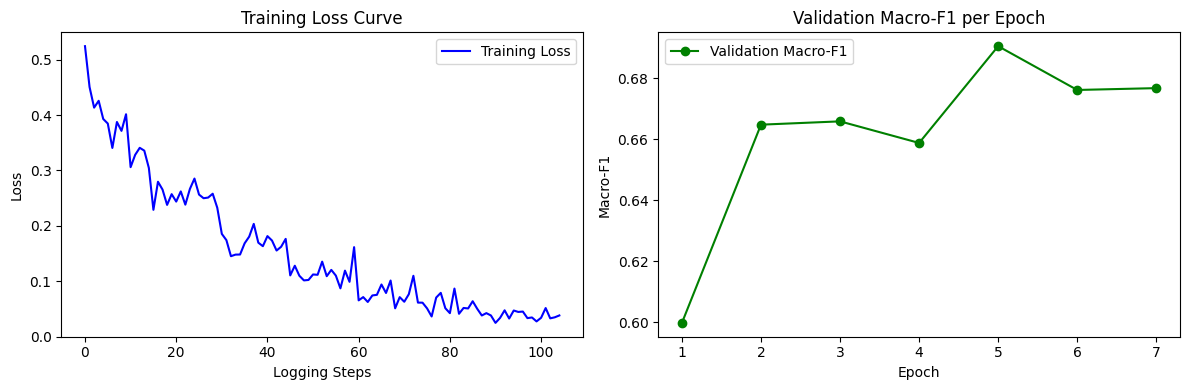

Đã lưu đồ thị học tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint07/learning_curves_checkpoint07.png


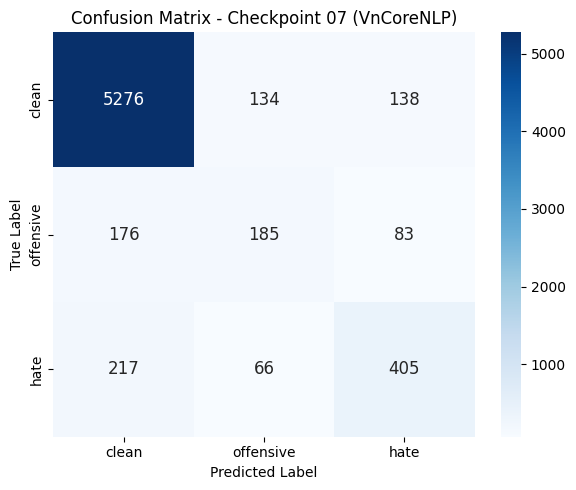

Đã lưu ma trận nhầm lẫn tại: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint07/confusion_matrix_checkpoint07.png


In [12]:
curves_output_path = os.path.join(outputs_dir, 'learning_curves_checkpoint07.png')
cm_output_path = os.path.join(outputs_dir, 'confusion_matrix_checkpoint07.png')

import matplotlib.pyplot as plt
import seaborn as sns

log_history = trainer.state.log_history
train_loss = [x['loss'] for x in log_history if 'loss' in x]
eval_f1 = [x['eval_macro_f1'] for x in log_history if 'eval_macro_f1' in x]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
if train_loss:
    ax1.plot(train_loss, label='Training Loss', color='blue')
    ax1.set_title('Training Loss Curve')
    ax1.set_xlabel('Logging Steps')
    ax1.set_ylabel('Loss')
    ax1.legend()
if eval_f1:
    ax2.plot(range(1, len(eval_f1) + 1), eval_f1, label='Validation Macro-F1', color='green', marker='o')
    ax2.set_title('Validation Macro-F1 per Epoch')
    ax2.set_xlabel('Epoch')
    ax2.set_ylabel('Macro-F1')
    ax2.legend()
plt.tight_layout()
plt.savefig(curves_output_path, dpi=300)
plt.show()
print(f'Đã lưu đồ thị học tại: {curves_output_path}')

df_cm = pd.DataFrame(results['confusion_matrix'], index=class_names, columns=class_names)
fig_cm, ax_cm = plt.subplots(figsize=(6, 5))
sns.heatmap(df_cm, annot=True, cmap='Blues', fmt='d', cbar=True, ax=ax_cm, annot_kws={'size': 12})
ax_cm.set_title('Confusion Matrix - Checkpoint 07 (VnCoreNLP)')
ax_cm.set_xlabel('Predicted Label')
ax_cm.set_ylabel('True Label')
plt.tight_layout()
plt.savefig(cm_output_path, dpi=300)
plt.show()
print(f'Đã lưu ma trận nhầm lẫn tại: {cm_output_path}')

## 10. Bảng Đối Sánh Ablation Study: PyVi (CP05) vs VnCoreNLP (CP07)

In [13]:
comparison_data = {
    'Mô Hình / Checkpoint': [
        'Baseline Gốc (Lưu et al., 2021)',
        'Checkpoint 01 (Baseline + Smoothed CW)',
        'Checkpoint 02 (Baseline + Focal Loss gamma = 1.5)',
        'Checkpoint 03 (Baseline + Tiền xử lý dữ liệu)',
        'Checkpoint 04 (Tối ưu hóa huấn luyện nâng cao)',
        'Checkpoint 05 (Tích hợp toàn diện với PyVi)',
        'Checkpoint 06 (Hiện đại hóa PhoBERT-base-v2)',
        'Checkpoint 07 (Tích hợp toàn diện với VnCoreNLP - Hiện tại)',
    ],
    'Bộ Tách Từ (Segmenter)': [
        'Không (fastBPE thô)', 'Không', 'Không', 'PyVi',
        'Không', 'PyVi', 'PyVi', 'VnCoreNLP (RDRsegmenter)',
    ],
    'Backbone': [
        'phobert-base', 'phobert-base', 'phobert-base', 'phobert-base',
        'phobert-base', 'phobert-base', 'phobert-base-v2', 'phobert-base',
    ],
    'Độ Dài': [100, 100, 100, 100, 256, 256, 256, 256],
    'Số Epochs': [2, 2, 2, 2, 8, 8, 8, 8],
    'Hàm Mất Mát': [
        'Cross-Entropy',
        'Weighted Cross-Entropy (Smoothed)',
        'Focal Loss (gamma = 1.5)',
        'Cross-Entropy',
        'Cross-Entropy',
        'Weighted Focal Loss (gamma = 1.5, alpha Smoothed)',
        'Weighted Focal Loss (gamma = 1.5, alpha Smoothed)',
        'Weighted Focal Loss (gamma = 1.5, alpha Calibrated)',
    ],
    'Accuracy': [0.8350, 0.8521, 0.8540, 0.8560, 0.8650, 0.8687, 0.8642, round(float(results['accuracy']), 4)],
    'Macro-Precision': [0.6400, 0.6582, 0.6610, 0.6635, 0.6720, 0.6607, 0.6521, round(float(results['macro_precision']), 4)],
    'Macro-Recall': [0.6200, 0.6415, 0.6450, 0.6480, 0.6580, 0.6776, 0.6597, round(float(results['macro_recall']), 4)],
    'Macro-F1': [0.6276, 0.6493, 0.6528, 0.6552, 0.6645, 0.6686, 0.6541, round(float(results['macro_f1']), 4)],
    'F1 Clean': [0.9020, 0.9125, 0.9140, 0.9150, 0.9210, 0.9357, 0.9347, round(float(results['per_class_f1']['clean']), 4)],
    'F1 Offensive': [0.4610, 0.4912, 0.4950, 0.5010, 0.5180, 0.4501, 0.4429, round(float(results['per_class_f1']['offensive']), 4)],
    'F1 Hate': [0.5200, 0.5442, 0.5495, 0.5496, 0.5545, 0.6200, 0.5849, round(float(results['per_class_f1']['hate']), 4)],
}

df_comparison = pd.DataFrame(comparison_data)
comparison_csv_path = os.path.join(outputs_dir, 'benchmark_comparison.csv')
df_comparison.to_csv(comparison_csv_path, index=False)

print('=' * 80)
print('BẢNG ĐỐI SÁNH HIỆU NĂNG ABLATION STUDY (PYVI VS VNCORENLP):')
print('=' * 80)
print(df_comparison.to_string(index=False))

BẢNG ĐỐI SÁNH HIỆU NĂNG ABLATION STUDY (PYVI VS VNCORENLP):
                                       Mô Hình / Checkpoint   Bộ Tách Từ (Segmenter)        Backbone  Độ Dài  Số Epochs                                         Hàm Mất Mát  Accuracy  Macro-Precision  Macro-Recall  Macro-F1  F1 Clean  F1 Offensive  F1 Hate
                            Baseline Gốc (Lưu et al., 2021)      Không (fastBPE thô)    phobert-base     100          2                                       Cross-Entropy    0.8350           0.6400        0.6200    0.6276    0.9020        0.4610   0.5200
                     Checkpoint 01 (Baseline + Smoothed CW)                    Không    phobert-base     100          2                   Weighted Cross-Entropy (Smoothed)    0.8521           0.6582        0.6415    0.6493    0.9125        0.4912   0.5442
          Checkpoint 02 (Baseline + Focal Loss gamma = 1.5)                    Không    phobert-base     100          2                            Focal Loss (gamma = 1.5) 

## 11. Xuất Các Tệp Kết Quả Chuẩn Hóa (Mandatory Artifacts Export)

In [14]:
predictions_csv_path = os.path.join(outputs_dir, 'predictions.csv')
scores_csv_path = os.path.join(outputs_dir, 'evaluation_scores.csv')
report_csv_path = os.path.join(outputs_dir, 'classification_report.csv')
cm_csv_path = os.path.join(outputs_dir, 'confusion_matrix.csv')

test_ids = list(range(len(test_y)))

df_predictions = pd.DataFrame({
    'id': test_ids,
    'text': test_X,
    'ground_truth': y_true,
    'predicted_label': y_pred,
})
df_predictions.to_csv(predictions_csv_path, index=False, encoding='utf-8')
print(f'1. Đã xuất tệp dự đoán: {predictions_csv_path}')

df_cm = pd.DataFrame(results['confusion_matrix'], index=class_names, columns=class_names)
df_cm.index.name = 'true_label'
df_cm.to_csv(cm_csv_path)
print(f'2. Đã xuất tệp dữ liệu ma trận nhầm lẫn: {cm_csv_path}')

acc_val = round(float(results.get('accuracy', accuracy_score(y_true, y_pred))), 4)
macro_p_val = round(float(results.get('macro_precision', precision_score(y_true, y_pred, average='macro', zero_division=0))), 4)
macro_r_val = round(float(results.get('macro_recall', recall_score(y_true, y_pred, average='macro', zero_division=0))), 4)
per_class_p = results.get('per_class_precision', {name: round(precision_score(y_true, y_pred, average=None, zero_division=0)[i], 4) for i, name in enumerate(class_names)})
per_class_r = results.get('per_class_recall', {name: round(recall_score(y_true, y_pred, average=None, zero_division=0)[i], 4) for i, name in enumerate(class_names)})

scores_summary = {
    'metric': [
        'accuracy',
        'macro_precision',
        'macro_recall',
        'macro_f1',
        'micro_f1',
        'precision_clean',
        'recall_clean',
        'f1_clean',
        'precision_offensive',
        'recall_offensive',
        'f1_offensive',
        'precision_hate',
        'recall_hate',
        'f1_hate',
    ],
    'value': [
        acc_val,
        macro_p_val,
        macro_r_val,
        round(results['macro_f1'], 4),
        round(results['micro_f1'], 4),
        round(per_class_p['clean'], 4),
        round(per_class_r['clean'], 4),
        round(results['per_class_f1']['clean'], 4),
        round(per_class_p['offensive'], 4),
        round(per_class_r['offensive'], 4),
        round(results['per_class_f1']['offensive'], 4),
        round(per_class_p['hate'], 4),
        round(per_class_r['hate'], 4),
        round(results['per_class_f1']['hate'], 4),
    ],
}
df_scores = pd.DataFrame(scores_summary)
df_scores.to_csv(scores_csv_path, index=False)
print(f'3. Đã xuất tệp điểm số tổng hợp: {scores_csv_path}')

report_dict = classification_report(y_true, y_pred, target_names=class_names, digits=4, output_dict=True)
accuracy_val = report_dict.pop('accuracy')

rows = []
for label in class_names:
    row = report_dict[label]
    rows.append({
        'class': label,
        'precision': round(row['precision'], 4),
        'recall': round(row['recall'], 4),
        'f1_score': round(row['f1-score'], 4),
        'support': int(row['support']),
    })

rows.append({
    'class': 'accuracy',
    'precision': None,
    'recall': None,
    'f1_score': round(accuracy_val, 4),
    'support': len(y_true),
})

for avg_type in ['macro avg', 'weighted avg']:
    row = report_dict[avg_type]
    rows.append({
        'class': avg_type,
        'precision': round(row['precision'], 4),
        'recall': round(row['recall'], 4),
        'f1_score': round(row['f1-score'], 4),
        'support': int(row['support']),
    })

df_report = pd.DataFrame(rows)
df_report.to_csv(report_csv_path, index=False)
print(f'4. Đã xuất tệp báo cáo phân loại chi tiết: {report_csv_path}')

1. Đã xuất tệp dự đoán: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint07/predictions.csv
2. Đã xuất tệp dữ liệu ma trận nhầm lẫn: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint07/confusion_matrix.csv
3. Đã xuất tệp điểm số tổng hợp: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint07/evaluation_scores.csv
4. Đã xuất tệp báo cáo phân loại chi tiết: /content/drive/MyDrive/NLP_PhoBert_ViHSD/outputs/checkpoint07/classification_report.csv


## 12. Thử Nghiệm Suy Luận Trực Quan (Interactive Inference)

Cung cấp hàm suy luận dự đoán trực quan `predict_sentence` tích hợp trọn vẹn bộ tiền xử lý `ViHSDPreprocessor` (VnCoreNLP RDRsegmenter) và mô hình PhoBERT-base tối ưu của Checkpoint 07.

In [15]:
import torch
import torch.nn.functional as F

# 1. Ánh xạ nhãn và tên lớp chuẩn hóa
id2label = {0: "CLEAN", 1: "OFFENSIVE", 2: "HATE"}


def predict_sentence(text, model, tokenizer, preprocessor=None, max_seq_length=256):
    """
    Hàm dự đoán nhãn phân loại (CLEAN / OFFENSIVE / HATE) cho một câu văn bản đầu vào
    với bộ tiền xử lý VnCoreNLP RDRsegmenter và mô hình PhoBERT-base tối ưu hóa.
    """
    model.eval()
    device = next(model.parameters()).device

    # Tiền xử lý dữ liệu với ViHSDPreprocessor (VnCoreNLP RDRsegmenter)
    processed_text = text
    if preprocessor is not None and hasattr(preprocessor, "transform_text"):
        processed_text = preprocessor.transform_text(text)
        if not processed_text.strip():
            processed_text = text  # Giữ lại văn bản gốc nếu tiền xử lý trả về rỗng

    # Mã hóa chuỗi đầu vào
    inputs = tokenizer(
        processed_text,
        truncation=True,
        padding=True,
        max_length=max_seq_length,
        return_tensors="pt",
    )
    inputs = {k: v.to(device) for k, v in inputs.items()}

    # Suy luận xác suất qua Softmax
    with torch.no_grad():
        outputs = model(**inputs)
        logits = outputs.logits
        probabilities = F.softmax(logits, dim=-1).squeeze(0).cpu().numpy()
        pred_label_id = int(torch.argmax(logits, dim=-1).item())

    return {
        "raw_text": text,
        "processed_text": processed_text,
        "predicted_id": pred_label_id,
        "predicted_label": id2label[pred_label_id],
        "probabilities": {id2label[i]: float(prob) for i, prob in enumerate(probabilities)},
    }


# ==============================================================================
# 2. Thực thi thử nghiệm suy luận trên các câu ví dụ
# ==============================================================================
sample_comments = [
    "vui vcl ae ơi",
    "mày nhìn mặt hãm vl đm",
    "chúc mọi người một ngày làm việc thật nhiều năng lượng và vui vẻ",
]

current_preprocessor = preprocessor if "preprocessor" in globals() else None

for sample in sample_comments:
    res = predict_sentence(
        text=sample,
        model=model,
        tokenizer=tokenizer,
        preprocessor=current_preprocessor,
        max_seq_length=max_seq_length if "max_seq_length" in globals() else 256,
    )
    print("-" * 60)
    print(f"Văn bản gốc:      {res['raw_text']}")
    if current_preprocessor is not None:
        print(f"Sau tiền xử lý:   {res['processed_text']}")
    print(f"Nhãn dự đoán:     {res['predicted_label']} (Lớp {res['predicted_id']})")
    print("Xác suất từng lớp:")
    for label_name, prob in res["probabilities"].items():
        print(f"  - {label_name:<10}: {prob * 100:6.2f}%")
print("-" * 60)

------------------------------------------------------------
Văn bản gốc:      vui vcl ae ơi
Sau tiền xử lý:   vui vờ cờ lờ anh_em ơi
Nhãn dự đoán:     CLEAN (Lớp 0)
Xác suất từng lớp:
  - CLEAN     :  64.05%
  - OFFENSIVE :  35.34%
  - HATE      :   0.62%
------------------------------------------------------------
Văn bản gốc:      mày nhìn mặt hãm vl đm
Sau tiền xử lý:   mày nhìn mặt hãm vãi lồn đụ má
Nhãn dự đoán:     HATE (Lớp 2)
Xác suất từng lớp:
  - CLEAN     :   1.82%
  - OFFENSIVE :   6.78%
  - HATE      :  91.40%
------------------------------------------------------------
Văn bản gốc:      chúc mọi người một ngày làm việc thật nhiều năng lượng và vui vẻ
Sau tiền xử lý:   chúc mọi người một ngày làm_việc thật nhiều năng_lượng và vui_vẻ
Nhãn dự đoán:     CLEAN (Lớp 0)
Xác suất từng lớp:
  - CLEAN     :  97.50%
  - OFFENSIVE :   1.68%
  - HATE      :   0.82%
------------------------------------------------------------
